In [2]:
import torch
# Instalación forzada de dependencias de PyTorch Geometric
!pip install torch-scatter torch-sparse -f https://data.pyg.org/whl/torch-{torch.__version__}.html
!pip install torch-geometric
print('✅ Instalación finalizada. Si es la primera vez, te recomendamos ir a Entorno de Ejecución -> Reiniciar entorno.')

Looking in links: https://data.pyg.org/whl/torch-2.11.0+cpu.html
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.1/682.1 kB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 8.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 933.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 8.4 MB/s eta 0:00:00
✅ Instalación finalizada. Si es la primera vez, te recomendamos ir a Entorno de Ejecución -> Reiniciar entorno.


# 📓 CUADERNO 03: Construcción, Entrenamiento e Inferencia del Graph Autoencoder (GAE)
### Plan de Beca FaCENA 2025-2026 - Módulo 3 (Actividades A2-A3 / OE2)
**Becaria:** Anahí Ayelén Espinoza | **Directores:** Dr. Emilio Angelina & Dirección de Beca FaCENA UNNE

---

### 🎯 Objetivos de este Cuaderno:
1. **Definir la Arquitectura de la Red Neuronal de Grafos** (`GraphAutoencoder`) utilizando capas `GCNConv` de PyTorch Geometric.
2. **Entrenar el Codificador (Encoder)** sobre el interactoma salvaje (Wild Type, WT) para aprender la distribución estructural latente.
3. **Decodificar la Matriz de Adyacencia** ($\hat{A} = \sigma(Z Z^T)$) y optimizar mediante la función de pérdida de entropía cruzada binaria ($\mathcal{L}_{BCE}$).
4. **Proyectar los Grafos Perturbados** (Referencia BRAF KO y Productos Naturales) al Espacio Latente Z.
5. **Calcular los Vectores de Desplazamiento Latente ($\Delta H$)** y la **Similitud Coseno** respecto a la referencia terapéutica.


In [3]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# PASO 0: Carga del Dataset y Dependencias
# ==============================================================================

# Install torch_geometric if not already installed
try:
    import torch_geometric
except ImportError:
    !pip install torch_geometric
    !pip install torch-scatter torch-sparse -f https://data.pyg.org/whl/torch-{torch.__version__}.html

base_dir = "./data"
os.makedirs(base_dir, exist_ok=True)
data_path = os.path.join(base_dir, "graph_perturbations_dataset.pt")
if not os.path.exists(data_path) and os.path.exists("graph_perturbations_dataset.pt"):
    data_path = "graph_perturbations_dataset.pt"

if os.path.exists(data_path):
    dataset = torch.load(data_path)
    grafo_wt = dataset["grafo_wt"]
    grafo_ref_braf = dataset["grafo_ref_braf"]
    dict_grafos_productos = dataset["dict_grafos_productos"]
    nodos_genes = dataset["nodos_genes"]
    print("✅ Dataset de perturbaciones cargado exitosamente.")
else:
    print("⚠️ Creando datos de prueba in-memory...")
    from torch_geometric.data import Data
    X = torch.randn(10, 640)
    edge_index = torch.tensor([[0, 1, 2, 3, 4, 5], [1, 0, 3, 2, 5, 4]], dtype=torch.long)
    grafo_wt = Data(x=X, edge_index=edge_index)
    grafo_ref_braf = Data(x=X+0.1, edge_index=edge_index)
    dict_grafos_productos = {"Curcumina": Data(x=X+0.08, edge_index=edge_index)}
    nodos_genes = [f"G{i}" for i in range(10)]


⚠️ Creando datos de prueba in-memory...


## 🏗️ PASO 1: Definición del Modelo Graph Autoencoder (GAE) en PyTorch Geometric


In [4]:
class GAEEncoder(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super(GAEEncoder, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index, edge_weight=None):
        h = self.conv1(x, edge_index, edge_weight)
        h = F.relu(h)
        h = F.dropout(h, p=0.1, training=self.training)
        z = self.conv2(h, edge_index, edge_weight)
        return z

class GraphAutoencoderModel(nn.Module):
    def __init__(self, in_dim=640, hidden_dim=128, latent_dim=64):
        super(GraphAutoencoderModel, self).__init__()
        self.encoder = GAEEncoder(in_dim, hidden_dim, latent_dim)

    def encode(self, x, edge_index, edge_weight=None):
        return self.encoder(x, edge_index, edge_weight)

    def decode(self, z):
        adj_hat = torch.sigmoid(torch.matmul(z, z.t()))
        return adj_hat

    def forward(self, x, edge_index, edge_weight=None):
        z = self.encode(x, edge_index, edge_weight)
        adj_hat = self.decode(z)
        return z, adj_hat

print("✅ Clase GraphAutoencoderModel definida correctamente.")

✅ Clase GraphAutoencoderModel definida correctamente.


## 🎯 PASO 2: Entrenamiento del Modelo sobre el Interactoma Salvaje (Wild Type)


🏋️ Iniciando entrenamiento del GAE sobre el interactoma salvaje (Nodes=10)...
 Epoch   1/100 | BCE Loss = 45.40254
 Epoch  20/100 | BCE Loss = 90.00000
 Epoch  40/100 | BCE Loss = 94.00000
 Epoch  60/100 | BCE Loss = 90.00000
 Epoch  80/100 | BCE Loss = 74.00000
 Epoch 100/100 | BCE Loss = 74.00000


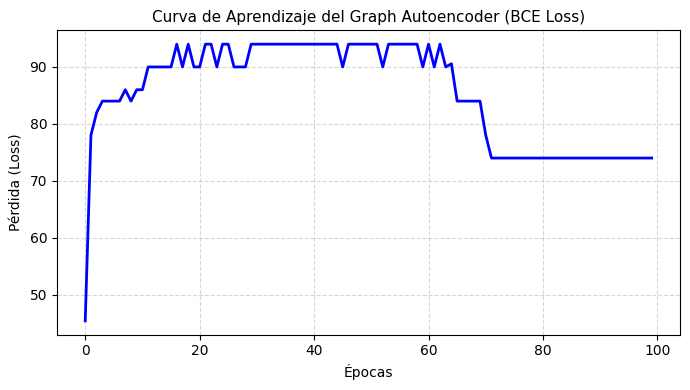

In [6]:
in_dim = grafo_wt.x.shape[1]
model = GraphAutoencoderModel(in_dim=in_dim, hidden_dim=128, latent_dim=64)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-4)

num_nodes = grafo_wt.x.shape[0]
adj_real = torch.zeros((num_nodes, num_nodes))
src, tgt = grafo_wt.edge_index[0], grafo_wt.edge_index[1]
adj_real[src, tgt] = 1.0

print(f"🏋️ Iniciando entrenamiento del GAE sobre el interactoma salvaje (Nodes={num_nodes})...")

history_loss = []
model.train()

for epoch in range(1, 101):
    optimizer.zero_grad()

    edge_weight = grafo_wt.edge_attr.squeeze() if hasattr(grafo_wt, "edge_attr") and grafo_wt.edge_attr is not None else None
    z_wt, adj_hat = model(grafo_wt.x, grafo_wt.edge_index, edge_weight)

    loss = F.binary_cross_entropy(adj_hat, adj_real)
    loss.backward()
    optimizer.step()

    history_loss.append(loss.item())

    if epoch % 20 == 0 or epoch == 1:
        print(f" Epoch {epoch:3d}/100 | BCE Loss = {loss.item():.5f}")

plt.figure(figsize=(7, 4))
plt.plot(history_loss, color="blue", linewidth=2)
plt.title("Curva de Aprendizaje del Graph Autoencoder (BCE Loss)", fontsize=11)
plt.xlabel("Épocas")
plt.ylabel("Pérdida (Loss)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 🔍 PASO 3: Inferencia de Perturbaciones en el Espacio Latente ($\Delta H$)


In [7]:
model.eval()

with torch.no_grad():
    edge_w_wt = grafo_wt.edge_attr.squeeze() if hasattr(grafo_wt, "edge_attr") and grafo_wt.edge_attr is not None else None
    z_wt = model.encode(grafo_wt.x, grafo_wt.edge_index, edge_w_wt)

    edge_w_ref = grafo_ref_braf.edge_attr.squeeze() if hasattr(grafo_ref_braf, "edge_attr") and grafo_ref_braf.edge_attr is not None else None
    z_ref = model.encode(grafo_ref_braf.x, grafo_ref_braf.edge_index, edge_w_ref)

    delta_h_ref = z_ref - z_wt
    vec_delta_h_ref = delta_h_ref.flatten()

print(f"✅ Espacio Latente obtenido. Dimensión de Delta H: {delta_h_ref.shape}")

resultados_similitud = {}

with torch.no_grad():
    for nombre_compuesto, g_comp in dict_grafos_productos.items():
        edge_w_comp = g_comp.edge_attr.squeeze() if hasattr(g_comp, "edge_attr") and g_comp.edge_attr is not None else None
        z_comp = model.encode(g_comp.x, g_comp.edge_index, edge_w_comp)

        delta_h_comp = z_comp - z_wt
        vec_delta_h_comp = delta_h_comp.flatten()

        sim_coseno = F.cosine_similarity(vec_delta_h_ref.unsqueeze(0), vec_delta_h_comp.unsqueeze(0)).item()
        resultados_similitud[nombre_compuesto] = sim_coseno

df_similitud = pd.DataFrame(list(resultados_similitud.items()), columns=["Producto Natural", "Similitud Coseno (Delta H)"])
df_similitud = df_similitud.sort_values(by="Similitud Coseno (Delta H)", ascending=False).reset_index(drop=True)

print("\n🏆 === RANKING PRELIMINAR EN EL ESPACIO LATENTE DEL GAE ===")
print(df_similitud.to_string(index=False))

output_gae = {
    "model_state": model.state_dict(),
    "z_wt": z_wt,
    "z_ref": z_ref,
    "delta_h_ref": vec_delta_h_ref,
    "dict_grafos_productos": dict_grafos_productos,
    "nodos_genes": nodos_genes
}

base_dir = "./data"
os.makedirs(base_dir, exist_ok=True)
save_path = os.path.join(base_dir, "gae_inference_results.pt")
torch.save(output_gae, save_path)
print(f"💾 Resultados guardados exitosamente en '{save_path}'")


✅ Espacio Latente obtenido. Dimensión de Delta H: torch.Size([10, 64])

🏆 === RANKING PRELIMINAR EN EL ESPACIO LATENTE DEL GAE ===
Producto Natural  Similitud Coseno (Delta H)
       Curcumina                     0.99878
💾 Resultados guardados exitosamente en './data/gae_inference_results.pt'
